# Theta metoda + Sobolova analýza


Notebook: původní Theta + SAPCE + Sobolova analýza; na konci kontrolní inverze tří nejvlivnějších vstupů pomocí UQpy.
Devět ostatních vstupů je pro každou kontrolní simulaci známo. Skutečný výsledek vyhodnoť podle diagnostiky a odložených dat.


In [3]:
import copy
import random
import traceback
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from UQpy.distributions import Normal, Uniform, JointIndependent
from UQpy.sampling.ThetaCriterionPCE import ThetaCriterionPCE

import SAPCE


In [4]:
# Načtení dat - ze souboru
def load_dataset(data_file):
    data = pd.read_csv(data_file, sep=";", header=0)

    for col in data.columns:
        if data[col].dtype == object:
            data[col] = pd.to_numeric(
                data[col].astype(str).str.replace(",", ".", regex=False),
                errors="raise"
            )

    arr = data.to_numpy()
    X = arr[:, :12]
    Y = arr[:, 12:]

    if X.shape[1] != 12:
        raise ValueError(f"Dataset {data_file} has {X.shape[1]} input columns, expected 12")

    if Y.shape[1] == 0:
        raise ValueError(f"Dataset {data_file} has no output columns after the first 12 columns")

    return X, Y


Nastavení

In [6]:
# Nastavení
DATA_FILES = [
    # "Oakwood_NVM.csv",
    # "Oakwood_N.csv",
    # "Oakwood_V.csv",
    "Oakwood_M.csv",
]

INPUT_NAMES = None

SEED = 1
N_REPEATS = 1
TEST_SIZE = 300

# Velikosti trénovací množiny
nsim = np.arange(15, 100, 10)

# Grid - pro různé soubory může být výhodné jiné nastavení SAPCE.
degree_list = [2, 3, 5]
cond_list = [10, 100, 1000]
cr_list = [1e-8]
ratio_list = [0.30, 0.40, 0.50, 0.70]

METHODS = ["Theta"]

# Theta zvolení kolik výstupů uvidí, None = všechny.
THETA_OUTPUT_INDICES = None

# Kontrola převodu PCE.
VERIFY_PCE_CONVERSION = True
PCE_VERIFY_ATOL = 1e-8
PCE_VERIFY_RTOL = 1e-6

n_inputs = 12
linear_terms = n_inputs + 1


In [7]:
# Rozdělení vstupů
marg = [
    Normal(13, 1),
    Uniform(30, 40),
    Uniform(2, 1),
    Normal(65, 5),
    Normal(30, 5),
    Normal(30, 1),
    Uniform(0.6, 0.5),
    Uniform(2, 1),
    Normal(130, 10),
    Normal(5, 1),
    Normal(42, 1),
    Uniform(0.45, 0.2)
]

joint = JointIndependent(marginals=marg)


In [8]:

# Univerzální predikce PCE objektu.
def predict_pce(pce, X_in):
    X_in = np.asarray(X_in, dtype=float)

    for name in ["predict", "evaluate", "run"]:
        if hasattr(pce, name):
            try:
                return np.asarray(getattr(pce, name)(X_in))
            except TypeError:
                pass

    if callable(pce):
        return np.asarray(pce(X_in))

    raise AttributeError("PCE object has no usable prediction method")


# Převod multi-output PCE na list jedno-výstupových PCE.
def pce_multioutput_to_singleoutput_list(pce, output_indices=None):
    coef = np.asarray(pce.coefficients)

    if coef.ndim == 1:
        coef = coef.reshape(-1, 1)

    n_outputs = coef.shape[1]

    if output_indices is None:
        output_indices = range(n_outputs)
    else:
        output_indices = [int(i) for i in output_indices]

    pce_list = []

    for j in output_indices:
        if j < 0 or j >= n_outputs:
            raise IndexError(f"output index {j} out of range")

        pce_j = copy.deepcopy(pce)
        pce_j.coefficients = coef[:, [j]]
        pce_list.append(pce_j)

    return pce_list


# Hlavní funkce pro ThetaCriterionPCE.
def select_theta_points_from_sapce(
    sapce,
    existing_samples,
    candidate_samples,
    nsamples=1,
    candidate_indices=None,
    output_indices=None,
    pce_weights=None,
    samples_weights=None,
    candidate_weights=None,
    verify_conversion=True,
    x_verify=None,
    atol=1e-8,
    rtol=1e-6,
):
    existing_samples = np.asarray(existing_samples, dtype=float)
    candidate_samples = np.asarray(candidate_samples, dtype=float)

    if candidate_samples.shape[0] == 0:
        raise ValueError("candidate_samples is empty")

    nsamples = int(nsamples)
    nsamples = max(1, min(nsamples, candidate_samples.shape[0]))

    pce_list = pce_multioutput_to_singleoutput_list(
        sapce.pce,
        output_indices=output_indices,
    )

    theta = ThetaCriterionPCE(pce_list)

    selected_pos = theta.run(
        existing_samples=existing_samples,
        candidate_samples=candidate_samples,
        nsamples=nsamples,
        samples_weights=samples_weights,
        candidate_weights=candidate_weights,
        pce_weights=pce_weights,
    )

    selected_pos = np.asarray(selected_pos, dtype=int).ravel()

    if selected_pos.size == 0:
        raise RuntimeError("ThetaCriterionPCE returned no selected positions")

    if np.any(selected_pos < 0) or np.any(selected_pos >= candidate_samples.shape[0]):
        raise IndexError(f"ThetaCriterionPCE returned positions outside candidate range: {selected_pos}")

    selected_global = None
    if candidate_indices is not None:
        candidate_indices = np.asarray(candidate_indices, dtype=int)
        selected_global = candidate_indices[selected_pos]

    return {
        "selected_pos": selected_pos,
        "selected_global_idx": selected_global,
        "conversion_info": None,
        "pce_list": pce_list,
    }


Funkce pro Sapce

In [10]:
def max_ratio_for_n(n_train):
    # Určí max. poměr
    min_ratio = (linear_terms + 0.5) / n_train

    if n_train < 30:
        base = 0.90
    elif n_train < 60:
        base = 0.70
    elif n_train < 100:
        base = 0.55
    elif n_train < 200:
        base = 0.60
    else:
        base = 0.70

    return min(0.95, max(base, min_ratio))


def ratio_candidates(n_train):
    # Vybere poměry
    upper = max_ratio_for_n(n_train)

    out = [
        r for r in ratio_list
        if r <= upper and int(np.floor(r * n_train)) >= linear_terms
    ]

    if len(out) == 0:
        out = [min(0.95, (linear_terms + 0.5) / n_train)]

    if not any(np.isclose(upper, r) for r in out):
        if int(np.floor(upper * n_train)) >= linear_terms:
            out.append(upper)

    return sorted(out)


def admissible_neighbors_fn():
    # Najde sousedy
    if hasattr(SAPCE, "admissible_neighbors"):
        return SAPCE.admissible_neighbors

    glb = SAPCE.SensitivityAdaptivePCE.construct_adaptive_basis.__globals__

    if "admissible_neighbors" in glb:
        return glb["admissible_neighbors"]

    raise RuntimeError("admissible_neighbors not found")


def filter_indices(indices, degree):
    # Filtruje indexy
    out = []

    for idx in indices:
        idx = np.asarray(idx, dtype=int)

        if np.sum(idx) <= degree and np.all(idx <= degree):
            out.append(idx.tolist())

    return out


def adaptive_basis_rollback(sapce, cond_limit, ratio_limit):
    # Staví bázi
    neigh = admissible_neighbors_fn()
    n_train = sapce.exp_design_in.shape[0]
    max_terms = int(np.floor(ratio_limit * n_train))

    while True:
        terms = len(sapce.pce.multi_index_set)

        if terms >= n_train:
            return "basis_ge_n_train"

        if terms >= max_terms:
            return "basis_ge_ratio"

        if sapce.condition_number > cond_limit:
            return "condition_too_large"

        new_idx = neigh(
            sapce.active_multi_indices[-1],
            sapce.active_multi_indices
        )

        new_idx = filter_indices(new_idx, sapce.max_partial_degree)

        if len(new_idx) == 0:
            return "no_new_indices"

        proposed_terms = (
            len(sapce.active_multi_indices)
            + len(sapce.admissible_multi_indices)
            + len(new_idx)
        )

        if proposed_terms >= n_train:
            return "proposed_ge_n_train"

        if proposed_terms > max_terms:
            return "proposed_ge_ratio"

        old_active = copy.deepcopy(sapce.active_multi_indices)
        old_admissible = copy.deepcopy(sapce.admissible_multi_indices)
        old_multi = copy.deepcopy(sapce.pce.multi_index_set)

        sapce.admissible_multi_indices += new_idx
        sapce.set_multi_index_set(
            sapce.active_multi_indices + sapce.admissible_multi_indices
        )
        sapce.compute_coefficients()

        if sapce.condition_number > cond_limit:
            sapce.active_multi_indices = old_active
            sapce.admissible_multi_indices = old_admissible
            sapce.set_multi_index_set(old_multi)
            sapce.compute_coefficients()

            return "rollback"

        i0 = len(sapce.active_multi_indices)
        coef = np.asarray(sapce.pce.coefficients[i0:])

        if coef.size == 0:
            return "no_coefficients"

        if coef.ndim == 1:
            score = np.abs(coef)
        else:
            score = np.sum(np.abs(coef), axis=1)

        best = int(np.argmax(score))
        sapce.active_multi_indices.append(
            sapce.admissible_multi_indices.pop(best)
        )


def make_split(n_total, test_size, max_train_size, seed):
    # Rozdělí indexy na nezávislý test a trénovací pool.
    # Testovací body se nesmí použít pro výběr konfigurace ani pro Theta.
    rng = random.Random(seed)
    idx = list(range(n_total))
    rng.shuffle(idx)

    test_idx = idx[:test_size]
    train_pool = idx[test_size:]

    if len(train_pool) < max_train_size:
        raise ValueError("Training pool is smaller than the requested maximum training size.")

    # Ponecháno kvůli kompatibilitě se zbytkem kódu.
    remaining_pool = []

    return test_idx, train_pool, remaining_pool


def split_data(X, Y, train_idx, test_idx):
    # Rozdělí data
    train_idx = np.asarray(train_idx, dtype=int)
    test_idx = np.asarray(test_idx, dtype=int)

    return X[train_idx], Y[train_idx], X[test_idx], Y[test_idx]


Konfigurace

In [12]:
# Nejlepší konfigurace

def maximum_absolute_error_per_output(pce, Xte, Yte):
    # Predikce
    y_pred = np.asarray(predict_pce(pce, Xte), dtype=float)

    # Skutečnost
    y_true = np.asarray(Yte, dtype=float)

    if y_pred.ndim == 1:
        y_pred = y_pred[:, None]

    if y_true.ndim == 1:
        y_true = y_true[:, None]

    if y_pred.shape != y_true.shape:
        raise ValueError(f"Prediction shape {y_pred.shape} does not match Yte shape {y_true.shape}")

    # Max chyba
    return np.max(np.abs(y_pred - y_true), axis=0)


def fit_one_config(Xtr, Ytr, Xte, Yte, degree, cond_limit, ratio_limit, cr, return_model=False):
    # SAPCE model
    sapce = SAPCE.SensitivityAdaptivePCE(
        pdf=joint,
        exp_design_in=Xtr,
        exp_design_out=Ytr,
        max_partial_degree=degree,
        num_inputs=12
    )

    # Adaptivní báze
    status = adaptive_basis_rollback(sapce, cond_limit, ratio_limit)

    # Počet členů
    terms_before = len(sapce.pce.multi_index_set)

    # Prořezání PCE
    sapce.construct_pruned_pce(cr=cr)

    # Počet členů
    terms_after = len(sapce.pce.multi_index_set)

    # Validační chyba
    err = np.asarray(sapce.pce.validation_error(Xte, Yte)).ravel()

    # Max chyba
    max_abs_err = maximum_absolute_error_per_output(sapce.pce, Xte, Yte)

    # Podmíněnost
    cond = float(sapce.condition_number)

    # Počet členů
    terms = len(sapce.pce.multi_index_set)

    # Poměr báze
    ratio = terms / Xtr.shape[0]

    # Platnost modelu
    valid = (
        np.all(np.isfinite(err))
        and np.all(err >= 0)
        and np.all(np.isfinite(max_abs_err))
        and np.all(max_abs_err >= 0)
        and cond <= cond_limit
        and terms < Xtr.shape[0]
        and ratio <= ratio_limit
    )

    # Výsledky
    out = {
        "degree": degree,
        "cond_limit": cond_limit,
        "ratio_limit": ratio_limit,
        "cr": cr,
        "err": err,
        "max_abs_err": max_abs_err,
        "mean": float(np.mean(err)),
        "median": float(np.median(err)),
        "max": float(np.max(err)),
        "max_abs_mean": float(np.mean(max_abs_err)),
        "max_abs_median": float(np.median(max_abs_err)),
        "max_abs_max": float(np.max(max_abs_err)),
        "cond": cond,
        "terms": terms,
        "ratio": ratio,
        "removed": terms_before - terms_after,
        "status": status,
        "valid": valid
    }

    # Vrácení modelu
    if return_model:
        out["sapce"] = sapce

    return out


def find_best_config(Xtr, Ytr, Xte, Yte, n_train):
    # Všechny výsledky
    results = []

    # Test konfigurací
    for degree in degree_list:
        for cond_limit in cond_list:
            for ratio_limit in ratio_candidates(n_train):
                for cr in cr_list:
                    try:
                        results.append(
                            fit_one_config(
                                Xtr, Ytr, Xte, Yte,
                                degree, cond_limit, ratio_limit, cr,
                                return_model=False,
                            )
                        )
                    except Exception:
                        pass

    # Platné modely
    valid = [r for r in results if r["valid"]]

    # Bez modelu
    if len(valid) == 0:
        return None, results

    # Skóre modelu
    def score(r):
        return (
            r["mean"]
            + 1e-5 * r["ratio"]
            + 1e-8 * np.log10(r["cond"] + 1.0)
        )

    # Nejlepší model
    return min(valid, key=score), results


def sobol_partial_variances(pce):
    alpha = np.asarray(pce.multi_index_set, dtype=int)
    coef = np.asarray(pce.coefficients, dtype=float)

    if coef.ndim == 1:
        coef = coef.reshape(-1, 1)

    if alpha.shape[0] != coef.shape[0]:
        raise ValueError("multi_index_set and coefficients have different number of terms")

    c2 = coef ** 2
    nonconst = np.any(alpha > 0, axis=1)
    n_active = np.sum(alpha > 0, axis=1)

    var = c2[nonconst].sum(axis=0)

    first = np.zeros((alpha.shape[1], coef.shape[1]))
    total = np.zeros_like(first)

    for i in range(alpha.shape[1]):
        has_i = alpha[:, i] > 0
        total[i] = c2[has_i].sum(axis=0)
        first[i] = c2[has_i & (n_active == 1)].sum(axis=0)

    return {"first": first, "total": total, "var": var}


In [13]:
# Theta výběr bodů.
def _find_best_config_for_theta(Xtr, Ytr, Xeval, Yeval, n_train):
    # Všechny výsledky
    results = []

    # Test konfigurací
    for degree in degree_list:
        for cond_limit in cond_list:
            for ratio_limit in ratio_candidates(n_train):
                for cr in cr_list:
                    try:
                        results.append(
                            fit_one_config(
                                Xtr, Ytr, Xeval, Yeval,
                                degree, cond_limit, ratio_limit, cr,
                                return_model=True,
                            )
                        )
                    except Exception:
                        pass

    # Platné modely
    valid = [r for r in results if r["valid"]]

    # Bez modelu
    if len(valid) == 0:
        return None, results

    # Skóre modelu
    def score(r):
        return (
            r["mean"]
            + 1e-5 * r["ratio"]
            + 1e-8 * np.log10(r["cond"] + 1.0)
        )

    # Nejlepší model včetně SAPCE objektu
    return min(valid, key=score), results


def build_theta_training_order(
    X,
    Y,
    initial_train_idx,
    candidate_pool,
    target_sizes,
):
    # Aktuální trénovací množina
    train_order = [int(i) for i in initial_train_idx]

    # Kandidáti pro Theta
    remaining_candidates = [int(i) for i in candidate_pool]

    theta_logs = []

    # Cílové velikosti trénovací množiny
    target_sizes = [int(n) for n in target_sizes]

    for target_size in target_sizes:
        # Pokud už máme dost bodů, pokračuj
        if len(train_order) >= target_size:
            theta_logs.append({
                "target_size": target_size,
                "n_before": len(train_order),
                "n_added": 0,
                "status": "already_enough",
                "degree": np.nan,
                "cond_limit": np.nan,
                "ratio_limit": np.nan,
                "cr": np.nan,
                "mean": np.nan,
                "max": np.nan,
                "fallback": False,
            })
            continue

        # Kolik bodů je potřeba doplnit
        n_to_add = target_size - len(train_order)

        # Pokud nejsou kandidáti, skonči
        if len(remaining_candidates) == 0:
            theta_logs.append({
                "target_size": target_size,
                "n_before": len(train_order),
                "n_added": 0,
                "status": "no_candidates",
                "degree": np.nan,
                "cond_limit": np.nan,
                "ratio_limit": np.nan,
                "cr": np.nan,
                "mean": np.nan,
                "max": np.nan,
                "fallback": True,
            })
            break

        n_to_add = min(n_to_add, len(remaining_candidates))

        Xtr = X[train_order]
        Ytr = Y[train_order]

        # Najdi nejlepší SAPCE model pouze podle aktuálních trénovacích bodů.
        # Nezávislá testovací množina se zde nepoužívá.
        best, all_results = _find_best_config_for_theta(
            Xtr,
            Ytr,
            Xtr,
            Ytr,
            len(train_order),
        )

        # Když model nejde sestavit, fallback = vezmi první dostupné kandidáty.
        if best is None:
            selected_global = remaining_candidates[:n_to_add]

            theta_logs.append({
                "target_size": target_size,
                "n_before": len(train_order),
                "n_added": len(selected_global),
                "status": "fallback_no_valid_model",
                "degree": np.nan,
                "cond_limit": np.nan,
                "ratio_limit": np.nan,
                "cr": np.nan,
                "mean": np.nan,
                "max": np.nan,
                "fallback": True,
            })

        else:
            try:
                theta_out = select_theta_points_from_sapce(
                    sapce=best["sapce"],
                    existing_samples=X[train_order],
                    candidate_samples=X[remaining_candidates],
                    nsamples=n_to_add,
                    candidate_indices=remaining_candidates,
                    output_indices=THETA_OUTPUT_INDICES,
                    verify_conversion=VERIFY_PCE_CONVERSION,
                    x_verify=Xtr,
                    atol=PCE_VERIFY_ATOL,
                    rtol=PCE_VERIFY_RTOL,
                )

                selected_global = [
                    int(i) for i in np.asarray(theta_out["selected_global_idx"]).ravel()
                ]

                theta_logs.append({
                    "target_size": target_size,
                    "n_before": len(train_order),
                    "n_added": len(selected_global),
                    "status": "theta_ok",
                    "degree": best["degree"],
                    "cond_limit": best["cond_limit"],
                    "ratio_limit": best["ratio_limit"],
                    "cr": best["cr"],
                    "mean": best["mean"],
                    "max": best["max"],
                    "fallback": False,
                })

            except Exception:
                # Když Theta selže, fallback = vezmi první dostupné kandidáty.
                selected_global = remaining_candidates[:n_to_add]

                theta_logs.append({
                    "target_size": target_size,
                    "n_before": len(train_order),
                    "n_added": len(selected_global),
                    "status": "fallback_theta_failed",
                    "degree": best["degree"],
                    "cond_limit": best["cond_limit"],
                    "ratio_limit": best["ratio_limit"],
                    "cr": best["cr"],
                    "mean": best["mean"],
                    "max": best["max"],
                    "fallback": True,
                })

        # Přidej vybrané body do trénovací množiny.
        train_order.extend(selected_global)

        # Odeber vybrané body z kandidátů.
        selected_set = set(selected_global)
        remaining_candidates = [
            i for i in remaining_candidates
            if i not in selected_set
        ]

    return train_order, theta_logs


In [14]:
# Jeden běh
def run_dataset(data_file, repeat_id=0, seed=SEED):
    dataset_name = os.path.splitext(os.path.basename(data_file))[0]

    X, Y = load_dataset(data_file)

    if INPUT_NAMES is not None:
        input_names = list(INPUT_NAMES)
    else:
        input_names = [
            str(c) for c in pd.read_csv(data_file, sep=";", header=0, nrows=0).columns[:X.shape[1]]
        ]

    max_train_size = int(np.max(nsim))

    # Split dat: 300 bodů je nezávislá testovací množina, zbytek je trénovací pool.
    test_idx, prefix_train_pool, remaining_pool = make_split(
        n_total=X.shape[0],
        test_size=TEST_SIZE,
        max_train_size=max_train_size,
        seed=seed,
    )

    initial_n = int(np.min(nsim))
    initial_train_idx = prefix_train_pool[:initial_n]

    # Kandidáti - pouze z trénovacího poolu, nikdy z testovací množiny.
    candidate_pool = [
        i for i in prefix_train_pool
        if i not in set(initial_train_idx)
    ]

    theta_full_order, theta_logs = build_theta_training_order(
        X=X,
        Y=Y,
        initial_train_idx=initial_train_idx,
        candidate_pool=candidate_pool,
        target_sizes=nsim,
    )

    train_indices_by_method = {
        "Theta": theta_full_order,
    }

    # Chyby
    errs_by_method = {
        method: np.full((len(nsim), Y.shape[1]), np.nan)
        for method in METHODS
    }

    # Max chyba
    max_abs_by_method = {
        method: np.full((len(nsim), Y.shape[1]), np.nan)
        for method in METHODS
    }

    rows = []
    sobol_final = None
    final_pce = None

    # Metody
    for method in METHODS:
        print(f"{dataset_name}_{method}_Seed {repeat_id + 1}/{N_REPEATS}")

        method_pool = train_indices_by_method[method]

        # Velikosti
        for i, n_train in enumerate(nsim):
            n_train = int(n_train)
            train_idx = method_pool[:n_train]

            Xtr = X[np.asarray(train_idx, dtype=int)]
            Ytr = Y[np.asarray(train_idx, dtype=int)]

            Xtest = X[np.asarray(test_idx, dtype=int)]
            Ytest = Y[np.asarray(test_idx, dtype=int)]

            # Najdi model pouze podle trénovacích dat.
            # Testovací množina se zde nepoužívá.
            best, all_results = find_best_config(
                Xtr,
                Ytr,
                Xtr,
                Ytr,
                n_train,
            )

            if best is None:
                rows.append({
                    "dataset": dataset_name,
                    "repeat": repeat_id,
                    "seed": seed,
                    "method": method,
                    "n_train": n_train,
                    "mean": np.nan,
                    "median": np.nan,
                    "max": np.nan,
                    "max_abs_mean": np.nan,
                    "max_abs_median": np.nan,
                    "max_abs_max": np.nan,
                    "condition": np.nan,
                    "basis_terms": np.nan,
                    "basis_ratio": np.nan,
                    "degree": np.nan,
                    "cond_limit": np.nan,
                    "ratio_limit": np.nan,
                    "cr": np.nan,
                    "valid_models": 0,
                    "tested_models": len(all_results),
                })
                continue

            # Finální vyhodnocení na nezávislé testovací množině.
            # Použije se konfigurace vybraná pouze z trénovacích dat.
            best_test = fit_one_config(
                Xtr,
                Ytr,
                Xtest,
                Ytest,
                best["degree"],
                best["cond_limit"],
                best["ratio_limit"],
                best["cr"],
                return_model=True,
            )

            if i == len(nsim) - 1:
                sobol_final = sobol_partial_variances(best_test["sapce"].pce)
                final_pce = best_test["sapce"].pce

            errs_by_method[method][i, :] = best_test["err"]
            max_abs_by_method[method][i, :] = best_test["max_abs_err"]

            rows.append({
                "dataset": dataset_name,
                "repeat": repeat_id,
                "seed": seed,
                "method": method,
                "n_train": n_train,
                "mean": best_test["mean"],
                "median": best_test["median"],
                "max": best_test["max"],
                "max_abs_mean": best_test["max_abs_mean"],
                "max_abs_median": best_test["max_abs_median"],
                "max_abs_max": best_test["max_abs_max"],
                "condition": best_test["cond"],
                "basis_terms": best_test["terms"],
                "basis_ratio": best_test["ratio"],
                "degree": best["degree"],
                "cond_limit": best["cond_limit"],
                "ratio_limit": best["ratio_limit"],
                "cr": best["cr"],
                "valid_models": sum(r["valid"] for r in all_results),
                "tested_models": len(all_results),
            })

    res = pd.DataFrame(rows)

    # Kontrola: žádná metoda nesmí použít testovací body.
    for method in METHODS:
        overlap = len(set(test_idx).intersection(set(train_indices_by_method[method])))

        if overlap != 0:
            raise AssertionError(f"Training and test sets overlap for method {method}")

    return {
        "dataset": dataset_name,
        "repeat": repeat_id,
        "seed": seed,
        "X_shape": X.shape,
        "Y_shape": Y.shape,
        "results": res,
        "errs_by_method": errs_by_method,
        "max_abs_by_method": max_abs_by_method,
        "theta_logs": theta_logs,
        "test_idx": test_idx,
        "prefix_train_pool": prefix_train_pool,
        "theta_full_order": theta_full_order,
        "sobol": sobol_final,
        "pce": final_pce,
        "input_names": input_names,
        "X": X,
        "Y": Y,
    }


# Všechny běhy
all_outputs = {
    os.path.splitext(os.path.basename(data_file))[0]: []
    for data_file in DATA_FILES
}

all_results = []

# Opakování
for repeat_id in range(N_REPEATS):
    repeat_seed = SEED + repeat_id

    # Datasety
    for data_file in DATA_FILES:
        out = run_dataset(
            data_file=data_file,
            repeat_id=repeat_id,
            seed=repeat_seed,
        )

        all_outputs[out["dataset"]].append(out)
        all_results.append(out["results"])

summary_df = pd.concat(all_results, ignore_index=True)

# Statistiky
stat_rows = []

for dataset_name, repeats in all_outputs.items():
    for method in METHODS:
        mean_curves = np.asarray([
            np.nanmean(rep["errs_by_method"][method], axis=1)
            for rep in repeats
        ])

        max_abs_curves = np.asarray([
            np.nanmax(rep["max_abs_by_method"][method], axis=1)
            for rep in repeats
        ])

        for i, n_train in enumerate(nsim):
            stat_rows.append({
                "dataset": dataset_name,
                "method": method,
                "n_train": int(n_train),
                "test_mean_avg": float(np.nanmean(mean_curves[:, i])),
                "test_mean_std": float(np.nanstd(mean_curves[:, i], ddof=1)),
                "test_mean_p05": float(np.nanpercentile(mean_curves[:, i], 5)),
                "test_mean_p95": float(np.nanpercentile(mean_curves[:, i], 95)),
                "max_abs_error_avg": float(np.nanmean(max_abs_curves[:, i])),
                "max_abs_error_std": float(np.nanstd(max_abs_curves[:, i], ddof=1)),
                "max_abs_error_p05": float(np.nanpercentile(max_abs_curves[:, i], 5)),
                "max_abs_error_p95": float(np.nanpercentile(max_abs_curves[:, i], 95)),
                "n_repeats": len(repeats),
            })

stats_df = pd.DataFrame(stat_rows)


Oakwood_M_Theta_Seed 1/1


# Grafy

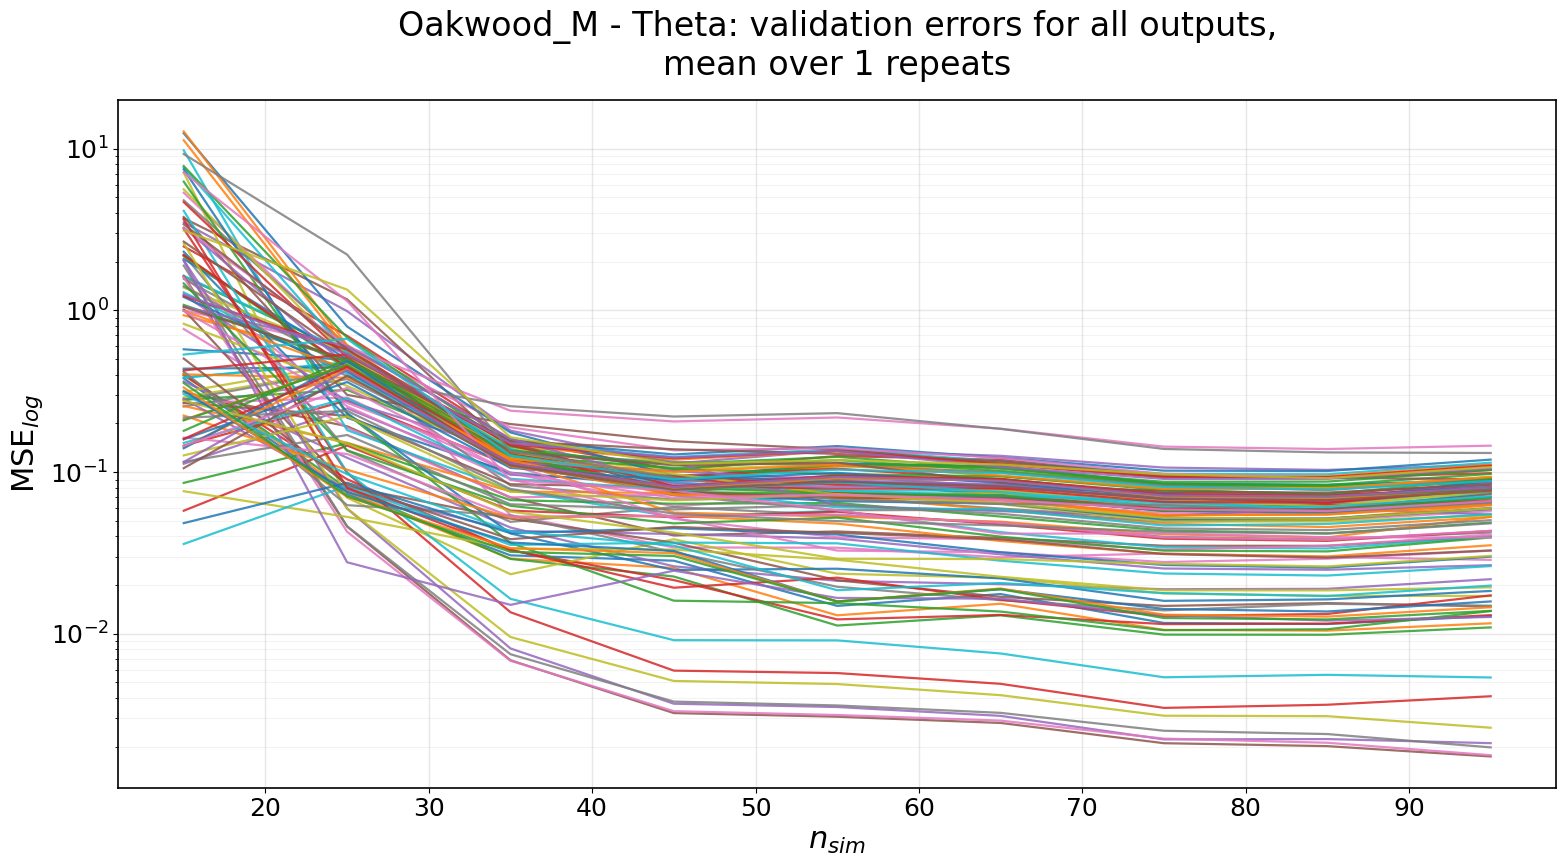

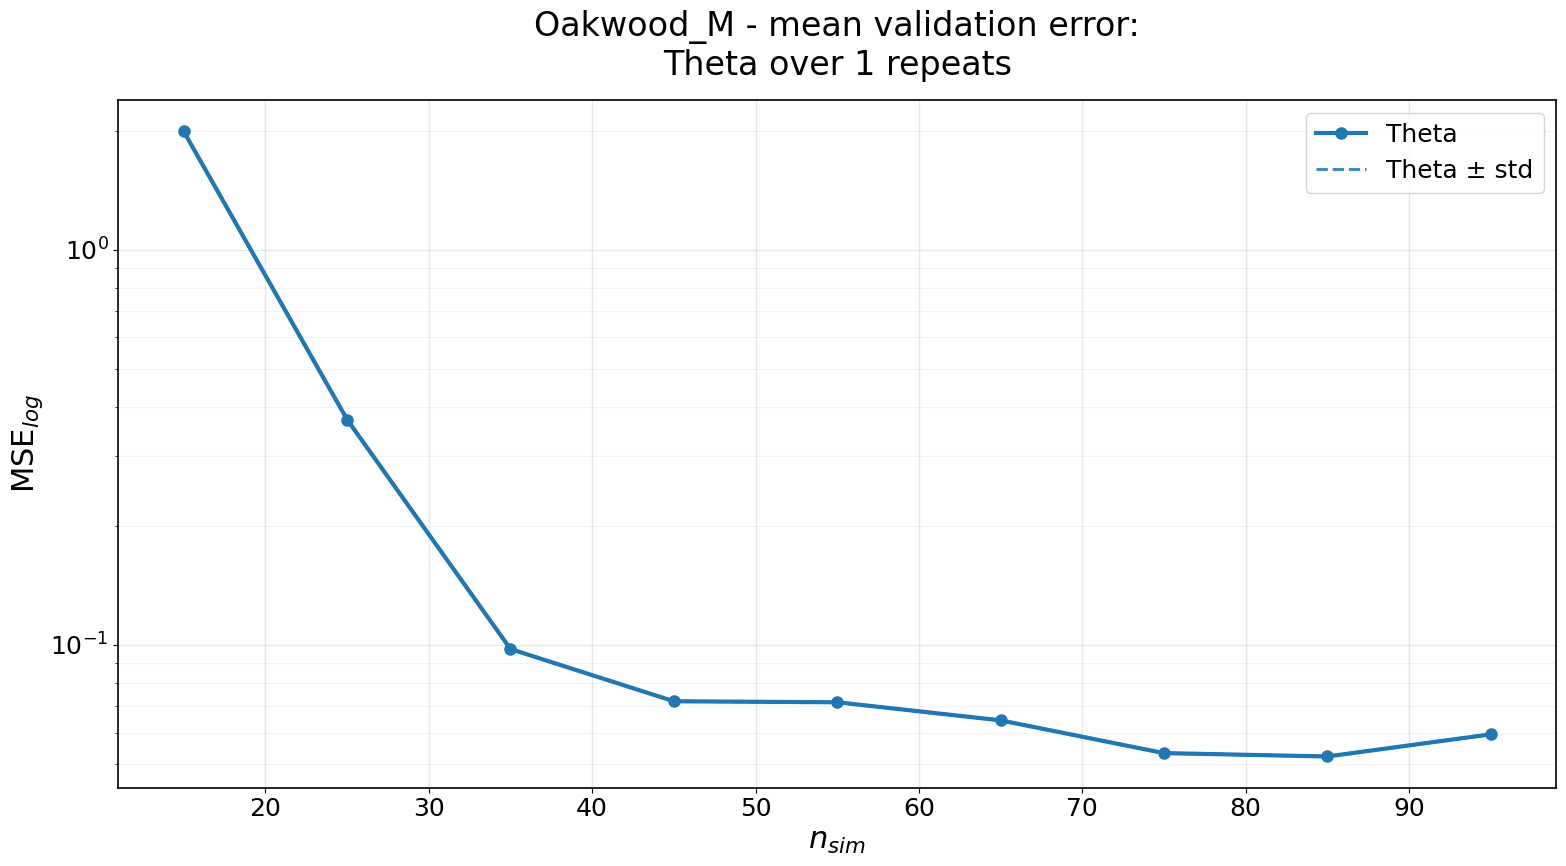

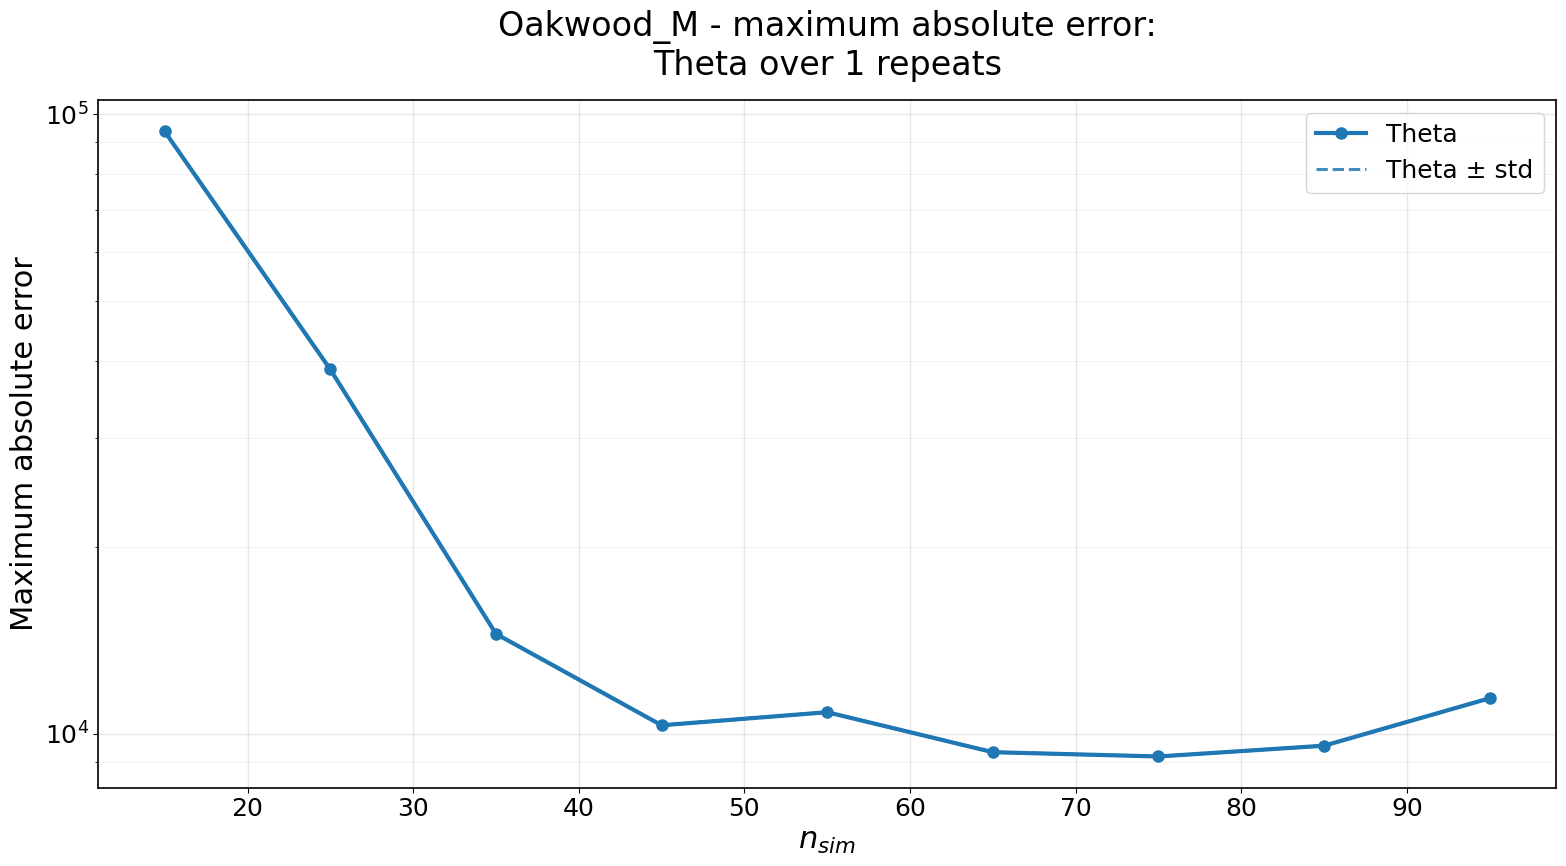

plots_output


In [16]:
# ============================================================
# Grafy
# ============================================================

import os
import re

# ------------------------------------------------------------
# Složka pro ukládání obrázků
# ------------------------------------------------------------

PLOTS_DIR = "plots_output"
os.makedirs(PLOTS_DIR, exist_ok=True)

SAVE_DPI = 300


def safe_filename(text):
    """Bezpečný název souboru bez mezer a speciálních znaků."""
    text = str(text)
    text = text.replace(" ", "_")
    text = re.sub(r"[^A-Za-z0-9_\-]+", "", text)
    return text


def save_current_figure(fig, dataset_name, plot_name):
    """Uloží aktuální obrázek do složky PLOTS_DIR."""
    filename = f"{safe_filename(dataset_name)}_{safe_filename(plot_name)}.png"
    filepath = os.path.join(PLOTS_DIR, filename)

    fig.savefig(
        filepath,
        dpi=SAVE_DPI,
        bbox_inches="tight",
        facecolor="white"
    )


# Globální nastavení velikostí pro prezentaci
PRESENTATION_FIGSIZE = (16, 9)

TITLE_SIZE = 24
LABEL_SIZE = 22
TICK_SIZE = 18
LEGEND_SIZE = 18

MAIN_LINEWIDTH = 3.0
STD_LINEWIDTH = 2.2
ALL_OUTPUT_LINEWIDTH = 1.6
MARKER_SIZE = 8

PLOT_METHODS = ["Theta"]

plt.rcParams.update({
    "font.size": TICK_SIZE,
    "axes.titlesize": TITLE_SIZE,
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "legend.fontsize": LEGEND_SIZE,
})


def format_presentation_axes(ax):
    """Jednotné formátování grafu pro prezentaci."""
    ax.tick_params(axis="both", which="major", labelsize=TICK_SIZE)
    ax.tick_params(axis="both", which="minor", labelsize=TICK_SIZE - 2)

    ax.grid(True, which="major", alpha=0.30, linewidth=1.0)
    ax.grid(True, which="minor", alpha=0.15, linewidth=0.8)

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)


def plot_mean_with_band(ax, x, curves, label):
    curves = np.asarray(curves, dtype=float)

    mean = np.nanmean(curves, axis=0)
    std = np.nanstd(curves, axis=0)

    lower = mean - std
    upper = mean + std

    # --------------------------------------------------------
    # Na logaritmické ose nelze vykreslit hodnoty <= 0.
    # Aby se čára směrodatné odchylky nikdy nepřerušila,
    # hodnoty <= 0 se oříznou na malou kladnou hodnotu.
    # --------------------------------------------------------

    positive_values = np.concatenate([
        mean[np.isfinite(mean) & (mean > 0)],
        lower[np.isfinite(lower) & (lower > 0)],
        upper[np.isfinite(upper) & (upper > 0)],
    ])

    if positive_values.size > 0:
        log_floor = np.nanmin(positive_values) * 0.50
    else:
        log_floor = 1e-12

    lower = np.where(np.isfinite(lower), lower, log_floor)
    upper = np.where(np.isfinite(upper), upper, log_floor)

    lower = np.maximum(lower, log_floor)
    upper = np.maximum(upper, log_floor)

    # Hlavní křivka = průměr
    line, = ax.plot(
        x,
        mean,
        marker="o",
        markersize=MARKER_SIZE,
        linewidth=MAIN_LINEWIDTH,
        label=label
    )

    # Barva dané metody
    color = line.get_color()

    # Dolní okraj = mean - směrodatná odchylka
    ax.plot(
        x,
        lower,
        linestyle="--",
        linewidth=STD_LINEWIDTH,
        color=color,
        alpha=0.85,
        label=f"{label} ± std"
    )

    # Horní okraj = mean + směrodatná odchylka
    ax.plot(
        x,
        upper,
        linestyle="--",
        linewidth=STD_LINEWIDTH,
        color=color,
        alpha=0.85,
        label="_nolegend_"
    )


for dataset_name, repeats in all_outputs.items():

    # ========================================================
    # 1) Graf všech výstupních křivek pro Theta
    #    průměr přes opakování
    # ========================================================

    theta_stack = np.asarray([
        rep["errs_by_method"]["Theta"]
        for rep in repeats
    ])  # repeat x n_train x n_outputs

    errs_theta_mean_outputs = np.nanmean(theta_stack, axis=0)

    fig, ax = plt.subplots(figsize=PRESENTATION_FIGSIZE)

    for j in range(errs_theta_mean_outputs.shape[1]):
        ax.plot(
            nsim,
            errs_theta_mean_outputs[:, j],
            linewidth=ALL_OUTPUT_LINEWIDTH,
            alpha=0.85
        )

    ax.set_yscale("log")
    ax.set_ylabel("MSE$_{log}$", fontsize=LABEL_SIZE)
    ax.set_xlabel("$n_{sim}$", fontsize=LABEL_SIZE)
    ax.set_title(
        f"{dataset_name} - Theta: validation errors for all outputs,\n"
        f"mean over {N_REPEATS} repeats",
        fontsize=TITLE_SIZE,
        pad=18
    )

    format_presentation_axes(ax)

    plt.tight_layout()

    save_current_figure(
        fig,
        dataset_name,
        "01_Theta_all_output_validation_errors"
    )

    plt.show()


    # ========================================================
    # 2) Mean validation error Theta
    #    se směrodatnou odchylkou
    # ========================================================

    fig, ax = plt.subplots(figsize=PRESENTATION_FIGSIZE)

    for method in PLOT_METHODS:
        mean_curves = [
            np.nanmean(rep["errs_by_method"][method], axis=1)
            for rep in repeats
        ]  # repeat x n_train

        plot_mean_with_band(ax, nsim, mean_curves, method)

    ax.set_yscale("log")
    ax.set_ylabel("MSE$_{log}$", fontsize=LABEL_SIZE)
    ax.set_xlabel("$n_{sim}$", fontsize=LABEL_SIZE)
    ax.set_title(
        f"{dataset_name} - mean validation error:\n"
        f"Theta over {N_REPEATS} repeats",
        fontsize=TITLE_SIZE,
        pad=18
    )

    ax.legend(fontsize=LEGEND_SIZE, frameon=True)
    format_presentation_axes(ax)

    plt.tight_layout()

    save_current_figure(
        fig,
        dataset_name,
        "02_Theta_mean_validation_error_std"
    )

    plt.show()


    # ========================================================
    # 3) Maximum absolute error: Theta
    #    se směrodatnou odchylkou
    # ========================================================

    fig, ax = plt.subplots(figsize=PRESENTATION_FIGSIZE)

    for method in PLOT_METHODS:
        max_abs_curves = [
            np.nanmax(rep["max_abs_by_method"][method], axis=1)
            for rep in repeats
        ]  # repeat x n_train

        plot_mean_with_band(ax, nsim, max_abs_curves, method)

    ax.set_yscale("log")
    ax.set_ylabel("Maximum absolute error", fontsize=LABEL_SIZE)
    ax.set_xlabel("$n_{sim}$", fontsize=LABEL_SIZE)
    ax.set_title(
        f"{dataset_name} - maximum absolute error:\n"
        f"Theta over {N_REPEATS} repeats",
        fontsize=TITLE_SIZE,
        pad=18
    )

    ax.legend(fontsize=LEGEND_SIZE, frameon=True)
    format_presentation_axes(ax)

    plt.tight_layout()

    save_current_figure(
        fig,
        dataset_name,
        "03_Theta_maximum_absolute_error_std"
    )

    plt.show()


print(PLOTS_DIR)


# Sobolova analýza



Oakwood_M: Sobol indices (variance-weighted over all outputs), n_train = 95
 input     S1     ST  ST-S1
  k0_2 0.5039 0.5102 0.0064
    Ec 0.2591 0.2682 0.0091
Erat_2 0.0938 0.0998 0.0060
  k0_1 0.0720 0.0763 0.0044
 E50_2 0.0453 0.0505 0.0053
 phi_2 0.0048 0.0084 0.0036
 E50_1 0.0017 0.0017 0.0000
   c_1 0.0007 0.0007 0.0000
   c_2 0.0006 0.0006 0.0000
   Rel 0.0005 0.0005 0.0000
Erat_1 0.0002 0.0002 0.0000
 phi_1 0.0001 0.0001 0.0000
Top 3 by ST: ['k0_2', 'Ec', 'Erat_2']
Top 3 by S1: ['k0_2', 'Ec', 'Erat_2']
Sum S1 = 0.983, Sum of top 3 ST = 0.878


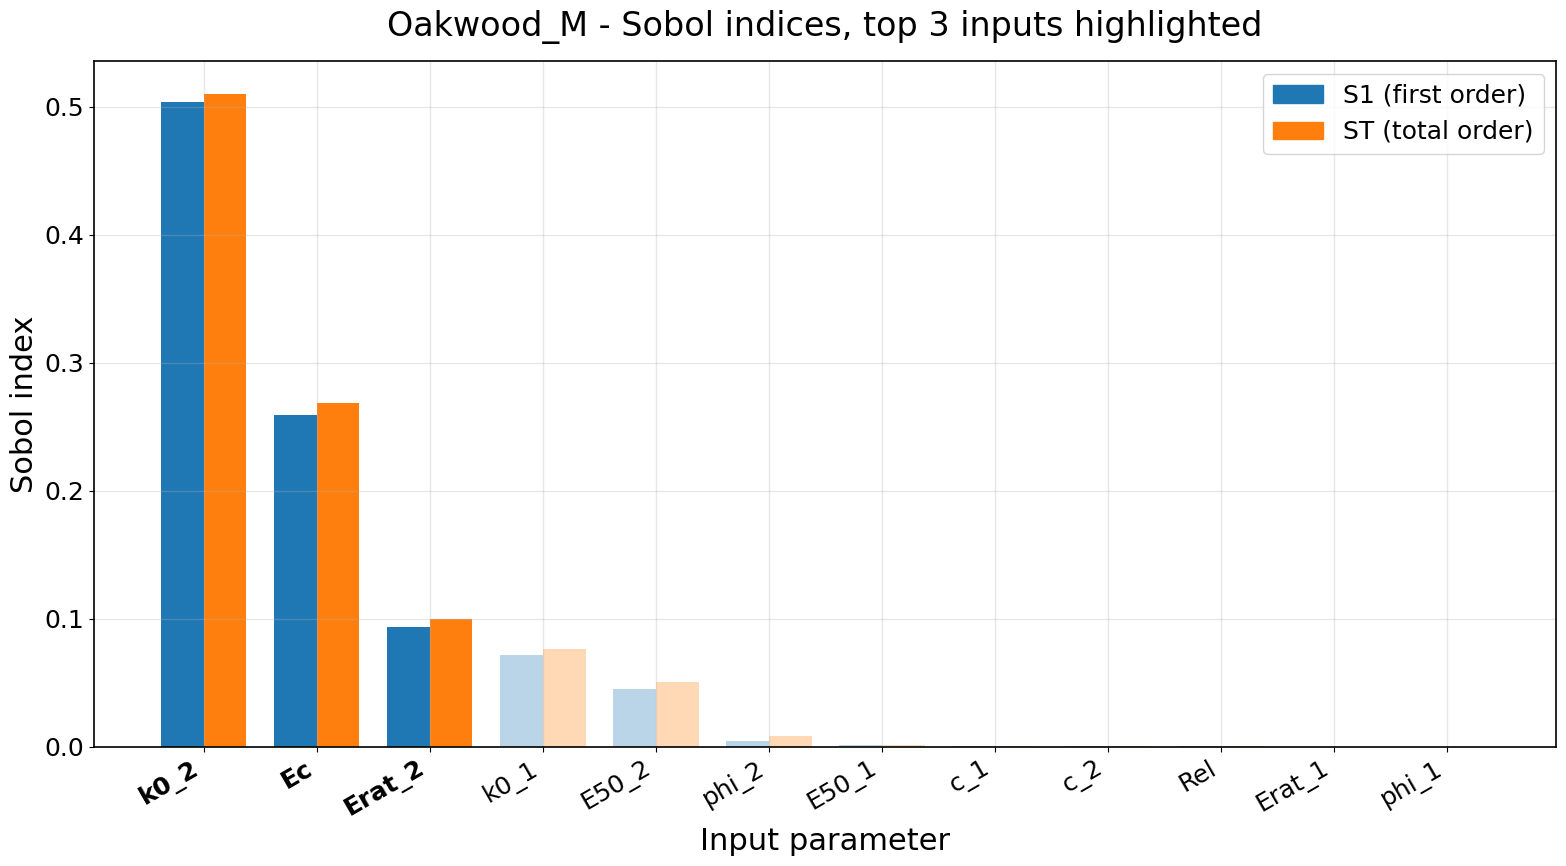

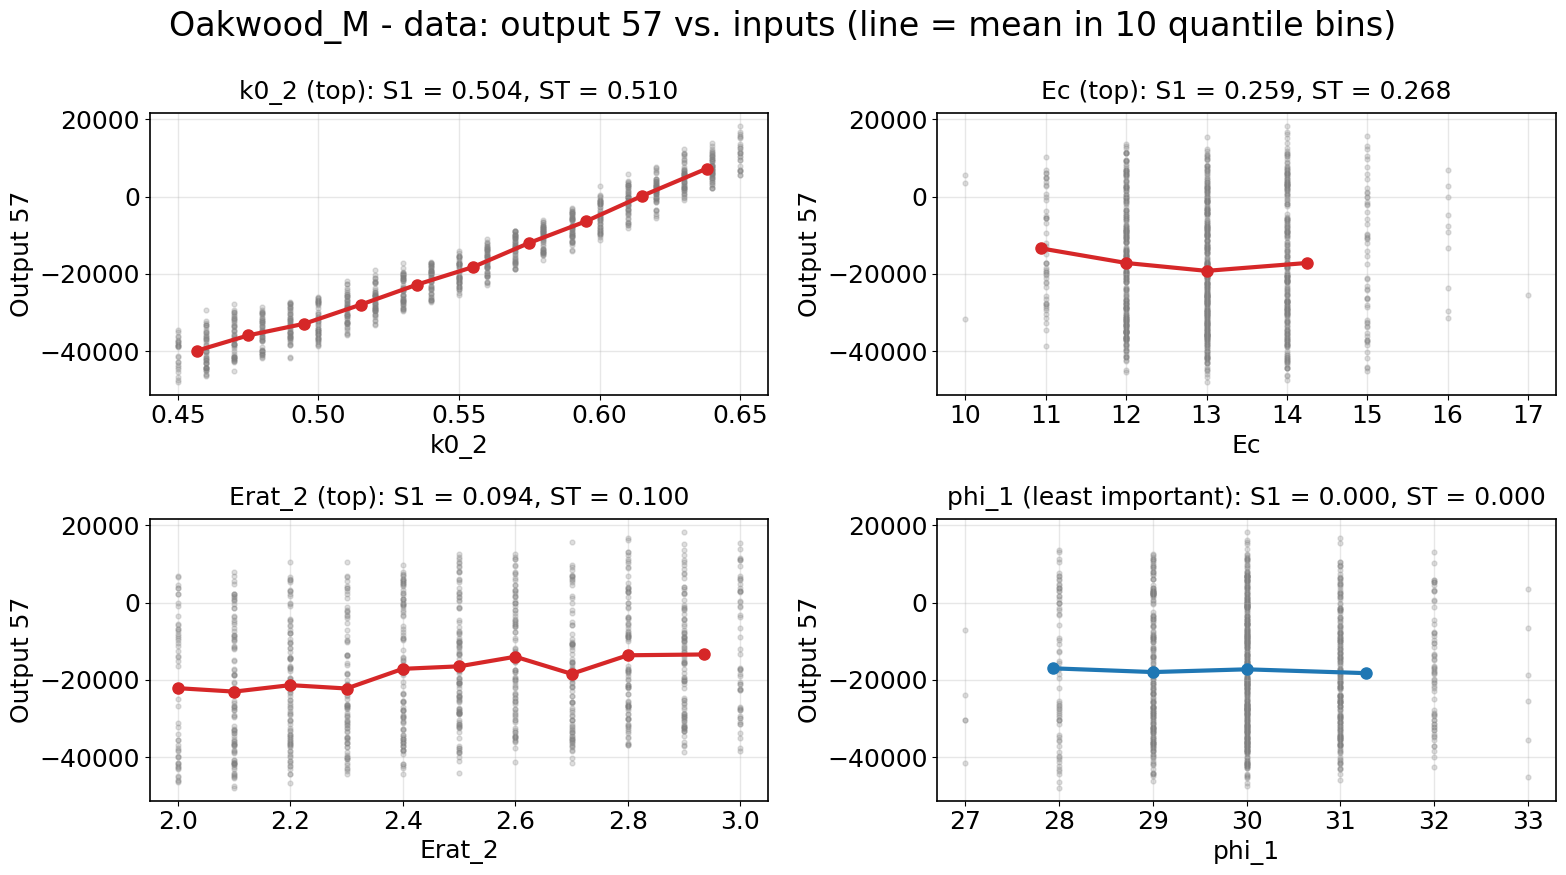

In [18]:
# ============================================================
# Sobolova analýza (první řád S1 a celkový ST)
# ============================================================

from matplotlib.patches import Patch

N_TOP = 3
N_BINS = 10

sobol_tables = {}
sobol_top = {}

for dataset_name, repeats in all_outputs.items():

    sob = [rep["sobol"] for rep in repeats if rep["sobol"] is not None]

    if len(sob) == 0:
        continue

    S1_rep = np.asarray([r["first"].sum(axis=1) / r["var"].sum() for r in sob])
    ST_rep = np.asarray([r["total"].sum(axis=1) / r["var"].sum() for r in sob])

    S1 = S1_rep.mean(axis=0)
    ST = ST_rep.mean(axis=0)
    S1_std = S1_rep.std(axis=0)
    ST_std = ST_rep.std(axis=0)

    n_in = S1.shape[0]
    names = [n.replace("$", r"\$") for n in repeats[0]["input_names"]]
    order = np.argsort(-ST)
    top = order[:N_TOP]
    top_S1 = np.argsort(-S1)[:N_TOP]
    sobol_top[dataset_name] = top

    table = pd.DataFrame({
        "input": [names[i] for i in order],
        "S1": S1[order],
        "ST": ST[order],
        "ST-S1": ST[order] - S1[order],
    })
    sobol_tables[dataset_name] = table

    print(f"\n{dataset_name}: Sobol indices (variance-weighted over all outputs), n_train = {int(nsim[-1])}")
    print(table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"Top {N_TOP} by ST: {[names[i] for i in top]}")
    print(f"Top {N_TOP} by S1: {[names[i] for i in top_S1]}")
    print(f"Sum S1 = {S1.sum():.3f}, Sum of top {N_TOP} ST = {ST[top].sum():.3f}")

    # ========================================================
    # 4) Sobolovy indexy S1 a ST všech vstupů
    # ========================================================

    fig, ax = plt.subplots(figsize=PRESENTATION_FIGSIZE)

    xpos = np.arange(n_in)
    width = 0.38
    is_top = np.isin(order, top)
    alphas = np.where(is_top, 1.0, 0.30)

    for k in range(n_in):
        i = order[k]
        ax.bar(
            xpos[k] - width / 2, S1[i], width,
            yerr=S1_std[i] if len(sob) > 1 else None,
            color="tab:blue", alpha=alphas[k], capsize=4
        )
        ax.bar(
            xpos[k] + width / 2, ST[i], width,
            yerr=ST_std[i] if len(sob) > 1 else None,
            color="tab:orange", alpha=alphas[k], capsize=4
        )

    ax.legend(
        handles=[
            Patch(color="tab:blue", label="S1 (first order)"),
            Patch(color="tab:orange", label="ST (total order)"),
        ],
        fontsize=LEGEND_SIZE,
        frameon=True
    )

    ax.set_xticks(xpos)
    ax.set_xticklabels([names[i] for i in order], rotation=30, ha="right")

    for lab, flag in zip(ax.get_xticklabels(), is_top):
        if flag:
            lab.set_fontweight("bold")

    ax.set_ylabel("Sobol index", fontsize=LABEL_SIZE)
    ax.set_xlabel("Input parameter", fontsize=LABEL_SIZE)
    ax.set_title(
        f"{dataset_name} - Sobol indices, top {N_TOP} inputs highlighted",
        fontsize=TITLE_SIZE,
        pad=18
    )

    format_presentation_axes(ax)

    plt.tight_layout()

    save_current_figure(
        fig,
        dataset_name,
        "04_Sobol_indices_S1_ST"
    )

    plt.show()

    # ========================================================
    # 5) Data: výstup v závislosti na třech nejdůležitějších
    #    vstupech a na nejméně důležitém vstupu
    # ========================================================

    X_all = repeats[0]["X"]
    Y_all = repeats[0]["Y"]

    j_out = int(np.argmax(np.var(Y_all, axis=0)))
    y_plot = Y_all[:, j_out]

    shown = list(top) + [int(order[-1])]

    fig, axes = plt.subplots(2, 2, figsize=PRESENTATION_FIGSIZE)

    for ax, i in zip(axes.ravel(), shown):
        x_i = X_all[:, i]

        ax.scatter(x_i, y_plot, s=12, alpha=0.25, color="tab:gray")

        edges = np.quantile(x_i, np.linspace(0.0, 1.0, N_BINS + 1))
        edges = np.unique(edges)
        bin_id = np.clip(np.digitize(x_i, edges[1:-1], right=False), 0, len(edges) - 2)

        xc = np.array([x_i[bin_id == b].mean() for b in range(len(edges) - 1)])
        yc = np.array([y_plot[bin_id == b].mean() for b in range(len(edges) - 1)])

        color = "tab:red" if i in top else "tab:blue"
        ax.plot(xc, yc, marker="o", markersize=MARKER_SIZE, linewidth=MAIN_LINEWIDTH, color=color)

        role = "top" if i in top else "least important"
        ax.set_title(
            f"{names[i]} ({role}): S1 = {S1[i]:.3f}, ST = {ST[i]:.3f}",
            fontsize=TITLE_SIZE - 6,
            pad=10
        )
        ax.set_xlabel(names[i], fontsize=LABEL_SIZE - 4)
        ax.set_ylabel(f"Output {j_out + 1}", fontsize=LABEL_SIZE - 4)

        format_presentation_axes(ax)

    fig.suptitle(
        f"{dataset_name} - data: output {j_out + 1} vs. inputs (line = mean in {N_BINS} quantile bins)",
        fontsize=TITLE_SIZE
    )

    plt.tight_layout()

    save_current_figure(
        fig,
        dataset_name,
        "05_Sobol_data_top_inputs"
    )

    plt.show()


# Inverzní analýza tří nejdůležitějších vstupů
Kalibrační, kontrolní a validační simulace jsou oddělené. Prior je připojen ke `LogLikelihoodModel` před vytvořením `BayesParameterEstimation`.

Inverzní analýzou zpětně odhaduji tři parametry vybrané podle Sobolových indexů z výstupů odložených simulací; zbývajících devět vstupů je při tomto testu známých. Odhady získám Bayesovskou metodou s modelem SAPCE a porovnám je se skutečnými hodnotami. Vypíšou se odhady a kontrolu MCMC a výsledky zobrazí v grafech.


Oakwood_M: podmíněná inverze; zbývajících 9 vstupů je známých
Parametry podle ST:
parametr     ST
    k0_2 0.5102
      Ec 0.2682
  Erat_2 0.0998
SAPCE na 172 kontrolních bodech: medián Q² = 0.934, medián norm. RMSE = 0.227, Q² < 0: 0 výstupů

Všech osm kontrolních simulací a všechny tři odhady:
 radek parametr     ST  skutecnost   odhad  abs_chyba  rel_chyba_pct  posterior_std   Rhat  vzorku_na_retezec  konvergence_MCMC
    34     k0_2 0.5102        0.62  0.6205     0.0005         0.0771         0.0011 1.0342               1200              True
    34       Ec 0.2682       14.00 14.6505     0.6505         4.6465         0.2181 1.0461               1200              True
    34   Erat_2 0.0998        2.40  2.4172     0.0172         0.7175         0.0367 1.0291               1200              True
   634     k0_2 0.5102        0.52  0.5204     0.0004         0.0740         0.0013 1.0330               1200              True
   634       Ec 0.2682       14.00 13.4505     0.5495         

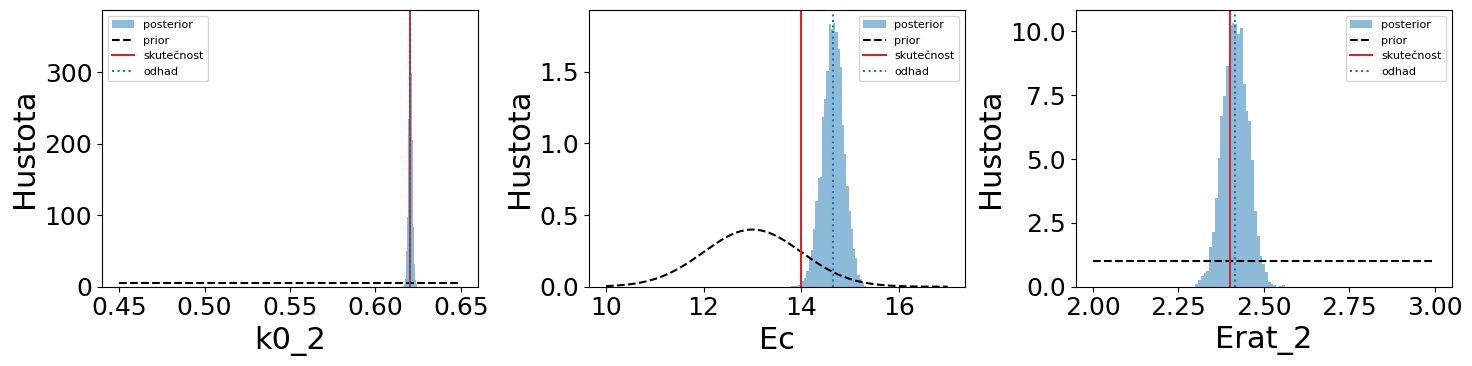

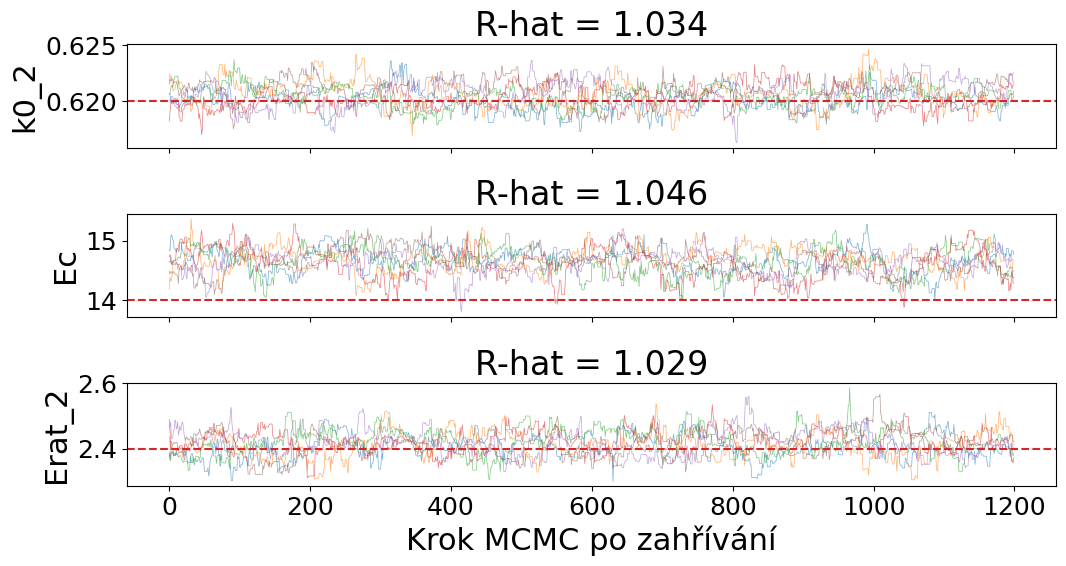

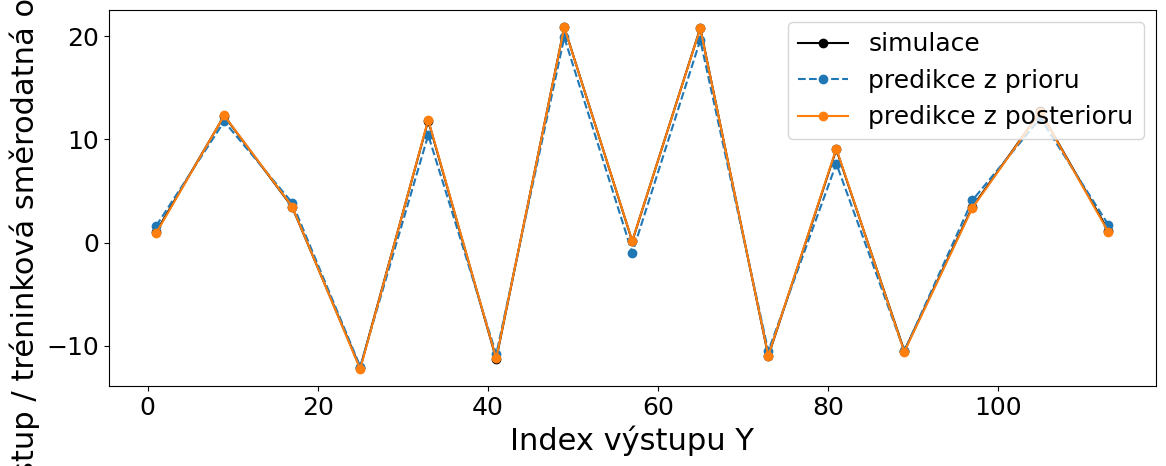

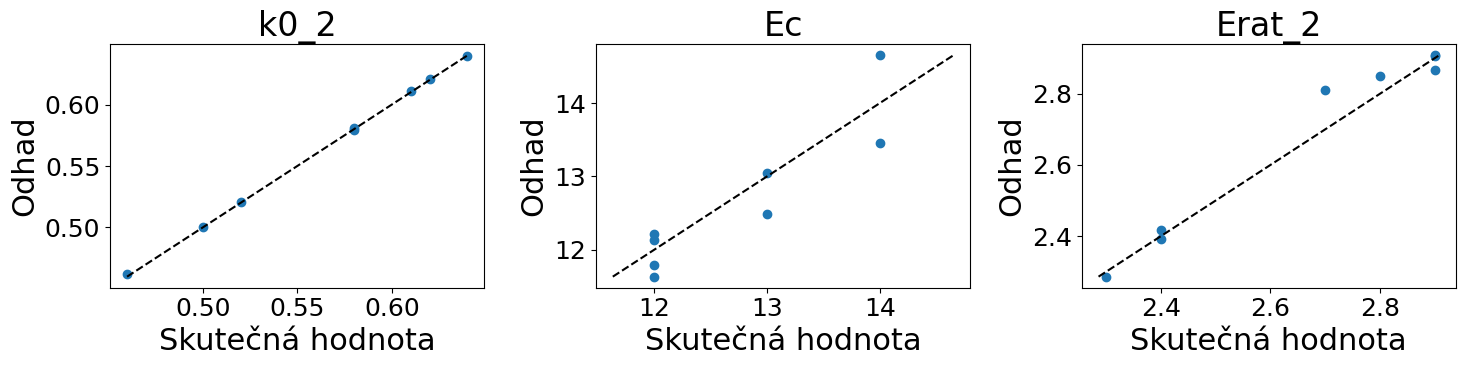

In [20]:
# Inverze tří vstupů s nejvyšším celkovým Sobolovým indexem
from scipy.linalg import solve_triangular
from sklearn.covariance import LedoitWolf
from UQpy.inference.BayesParameterEstimation import BayesParameterEstimation
from UQpy.inference.inference_models.LogLikelihoodModel import LogLikelihoodModel
from UQpy.sampling.mcmc.Stretch import Stretch

N_DEMO = 8                # Počet odložených simulací, na kterých ověřím inverzi.
N_CAL = 120               # Počet simulací pro odhad chyby modelu SAPCE.
N_CHAINS = 12             # Počet souběžných MCMC řetězců.
BURN_LENGTH = 1000        # Počáteční kroky každého řetězce, které zahodím.
N_SAMPLES_PER_CHAIN = 800 # První sada ponechaných vzorků z každého řetězce.
N_EXTRA = 400             # Kolik vzorků na řetězec přidám při vysokém R-hat.
N_MAX_PER_CHAIN = 2400    # Nejvyšší počet ponechaných vzorků na řetězec.
RHAT_LIMIT = 1.05         # Hranice pro kontrolu shody řetězců.
N_PRED = 250              # Počet vzorků použitých k výpočtu predikcí pro graf.
NOISE_FLOOR = 0.02        # Regularizace kovariance, nikoli známá chyba měření.  


def split_rhat(chains):
    n = chains.shape[0] // 2
    s = np.concatenate([chains[:n], chains[n:2 * n]], axis=1)
    w = s.var(axis=0, ddof=1).mean()
    b = n * s.mean(axis=0).var(ddof=1)
    return np.sqrt((n - 1) / n + b / (n * w)) if w > 0 else np.nan


os.makedirs("inverze_vysledky", exist_ok=True)
inverse_tables = {}

for dataset_name, repeats in all_outputs.items():
    rep = repeats[0]
    pce = rep["pce"]

    if pce is None or dataset_name not in sobol_top:
        raise RuntimeError("Chybí finální SAPCE model nebo Sobolovy indexy.")

    X_all = np.asarray(rep["X"], dtype=float)
    Y_all = np.asarray(rep["Y"], dtype=float)
    test_idx = np.asarray(rep["test_idx"], dtype=int)
    train_idx = np.asarray(
        rep["theta_full_order"][:int(nsim[-1])],
        dtype=int
    )
    names = list(rep["input_names"])

    # Vyberu tři parametry s nejvyšším ST přes všechny výstupy.
    sob = rep["sobol"]
    ST = sob["total"].sum(axis=1) / sob["var"].sum()
    top = np.argsort(-ST)[:3]

    if not np.array_equal(
        top,
        np.asarray(sobol_top[dataset_name][:3])
    ):
        raise AssertionError(
            "Pořadí parametrů neodpovídá Sobolově analýze."
        )

    pd.DataFrame({
        "parametr": names,
        "ST": ST
    }).sort_values(
        "ST", ascending=False
    ).to_csv(
        f"inverze_vysledky/{dataset_name}_Sobol_ST.csv",
        index=False
    )

    # Pro jednotlivé kroky používám různé odložené simulace.
    if len(test_idx) <= N_CAL + N_DEMO:
        raise ValueError("Pro zadané rozdělení chybí odložené body.")

    cal_idx = test_idx[:N_CAL]
    demo_idx = test_idx[N_CAL:N_CAL + N_DEMO]
    check_idx = test_idx[N_CAL + N_DEMO:]

    if set(train_idx) & set(test_idx):
        raise AssertionError("Trénink se překrývá s odloženými body.")

    y_scale = Y_all[train_idx].std(axis=0, ddof=1)

    if np.any(~np.isfinite(y_scale)) or np.any(y_scale <= 0):
        raise ValueError("Neplatný rozptyl některého výstupu.")

    def predict_norm(X):
        pred = np.asarray(predict_pce(pce, X), dtype=float)

        if (
            pred.shape != (len(X), Y_all.shape[1])
            or not np.isfinite(pred).all()
        ):
            raise ValueError("SAPCE vrátil neplatné predikce.")

        return pred / y_scale

    # Chybu SAPCE odhaduji při správných hodnotách všech 12 vstupů.
    residual = (
        Y_all[cal_idx] / y_scale
        - predict_norm(X_all[cal_idx])
    )
    bias = residual.mean(axis=0)

    cov = (
        LedoitWolf().fit(residual).covariance_
        + NOISE_FLOOR ** 2 * np.eye(Y_all.shape[1])
    )
    L = np.linalg.cholesky(cov)

    # Přesnost SAPCE kontroluji na dalších odložených bodech.
    y_check = Y_all[check_idx] / y_scale
    p_check = predict_norm(X_all[check_idx]) + bias
    rss = np.sum((y_check - p_check) ** 2, axis=0)
    tss = np.sum(
        (y_check - y_check.mean(axis=0)) ** 2,
        axis=0
    )
    q2 = np.where(
        tss > 0,
        1 - rss / np.maximum(tss, 1e-30),
        np.nan
    )
    rmse = np.sqrt(
        np.mean((y_check - p_check) ** 2, axis=0)
    )

    pd.DataFrame({
        "vystup": np.arange(1, Y_all.shape[1] + 1),
        "Q2": q2,
        "RMSE_norm": rmse
    }).to_csv(
        f"inverze_vysledky/{dataset_name}_presnost_SAPCE.csv",
        index=False
    )

    prior = JointIndependent(
        marginals=[marg[i] for i in top]
    )
    rows = []
    main = None

    for k, idx in enumerate(demo_idx):
        # Inverzuji tři vstupy. Zbývajících devět je známých.
        x_known = X_all[idx].copy()
        y_obs = Y_all[idx] / y_scale
        theta_true = X_all[idx, top]

        def forward(theta):
            theta = np.atleast_2d(
                np.asarray(theta, dtype=float)
            )
            Xf = np.tile(x_known, (len(theta), 1))
            Xf[:, top] = theta
            return predict_norm(Xf) + bias

        def log_likelihood(data, params):
            r = np.asarray(data)[None, :] - forward(params)
            z = solve_triangular(
                L,
                r.T,
                lower=True,
                check_finite=False
            )
            return -0.5 * np.sum(z ** 2, axis=0)

        model = LogLikelihoodModel(
            n_parameters=3,
            log_likelihood=log_likelihood
        )
        model.prior = prior

        initial = np.asarray(
            prior.rvs(
                nsamples=N_CHAINS,
                random_state=SEED + k
            ),
            dtype=float
        )

        if initial.shape != (N_CHAINS, 3):
            raise ValueError(
                "Nesprávný tvar počátečních bodů MCMC."
            )

        sampler = Stretch(
            log_pdf_target=model.evaluate_log_posterior,
            args_target=(y_obs,),
            burn_length=BURN_LENGTH,
            dimension=3,
            seed=initial.tolist(),
            n_chains=N_CHAINS,
            concatenate_chains=False,
            random_state=SEED + 100 + k,
        )

        bayes = BayesParameterEstimation(
            inference_model=model,
            data=y_obs,
            sampling_class=sampler,
            nsamples=N_CHAINS * N_SAMPLES_PER_CHAIN,
        )

        # Pokud R-hat nestačí, prodloužím stejné řetězce.
        while True:
            chains = np.asarray(
                bayes.sampler.samples,
                dtype=float
            )

            if (
                chains.ndim != 3
                or chains.shape[1:] != (N_CHAINS, 3)
                or not np.isfinite(chains).all()
            ):
                raise ValueError(
                    f"Neplatné MCMC vzorky: {chains.shape}"
                )

            rh = np.array([
                split_rhat(chains[:, :, j])
                for j in range(3)
            ])

            if (
                np.isfinite(rh).all()
                and np.max(rh) <= RHAT_LIMIT
            ):
                break

            if chains.shape[0] >= N_MAX_PER_CHAIN:
                break

            extra = min(
                N_EXTRA,
                N_MAX_PER_CHAIN - chains.shape[0]
            )
            bayes.run(nsamples=N_CHAINS * extra)

        converged = bool(
            np.isfinite(rh).all()
            and np.max(rh) <= RHAT_LIMIT
        )

        flat = chains.reshape(-1, 3)
        mean = flat.mean(axis=0)
        std = flat.std(axis=0, ddof=1)

        for j, col in enumerate(top):
            rows.append({
                "radek": idx,
                "parametr": names[col],
                "ST": ST[col],
                "skutecnost": theta_true[j],
                "odhad": mean[j],
                "abs_chyba": abs(
                    mean[j] - theta_true[j]
                ),
                "rel_chyba_pct": (
                    100 * abs(mean[j] - theta_true[j])
                    / abs(theta_true[j])
                    if theta_true[j] != 0 else np.nan
                ),
                "posterior_std": std[j],
                "Rhat": rh[j],
                "vzorku_na_retezec": chains.shape[0],
                "konvergence_MCMC": converged,
            })

        if k == 0:
            main = (
                chains,
                flat,
                theta_true,
                y_obs,
                x_known.copy()
            )

    # Všech osm případů × všechny tři parametry.
    table = pd.DataFrame(rows)
    inverse_tables[dataset_name] = table
    table.to_csv(
        f"inverze_vysledky/{dataset_name}_odhady.csv",
        index=False
    )

    # Srovnám chybu inverze s odhadem z průměru vstupů.
    baseline = X_all[train_idx[:, None], top].mean(axis=0)

    summary = table.groupby(
        "parametr",
        sort=False
    ).agg(
        RMSE=(
            "abs_chyba",
            lambda x: np.sqrt(np.mean(x ** 2))
        ),
        MAE=("abs_chyba", "mean"),
        max_abs_chyba=("abs_chyba", "max"),
        prumerna_rel_chyba_pct=("rel_chyba_pct", "mean"),
        prumerna_posterior_std=("posterior_std", "mean"),
        max_Rhat=("Rhat", "max"),
        konvergovalo_z_8=("konvergence_MCMC", "sum"),
    ).reset_index()

    summary["RMSE_vychozi_odhad"] = [
        np.sqrt(np.mean(
            (
                baseline[j]
                - table.loc[
                    table.parametr == names[col],
                    "skutecnost"
                ].to_numpy()
            ) ** 2
        ))
        for j, col in enumerate(top)
    ]

    summary["lepsi_nez_vychozi_odhad"] = (
        summary.RMSE < summary.RMSE_vychozi_odhad
    )
    summary.to_csv(
        f"inverze_vysledky/{dataset_name}_souhrn.csv",
        index=False
    )

    print(
        f"\n{dataset_name}: podmíněná inverze; "
        "zbývajících 9 vstupů je známých"
    )
    print("Parametry podle ST:")
    print(
        pd.DataFrame({
            "parametr": [names[i] for i in top],
            "ST": ST[top]
        }).round(4).to_string(index=False)
    )
    print(
        f"SAPCE na {len(check_idx)} kontrolních bodech: "
        f"medián Q² = {np.nanmedian(q2):.3f}, "
        f"medián norm. RMSE = {np.median(rmse):.3f}, "
        f"Q² < 0: {np.sum(q2 < 0)} výstupů"
    )
    print(
        "\nVšech osm kontrolních simulací "
        "a všechny tři odhady:"
    )
    print(table.round(4).to_string(index=False))
    print("\nSouhrn přesnosti:")
    print(summary.round(4).to_string(index=False))

    if not table.konvergence_MCMC.all():
        print(
            "POZOR: některé běhy nesplnily limit R-hat; "
            "jejich odhady nejsou ověřené."
        )

    if np.nanmedian(q2) < 0.5 or np.any(q2 < 0):
        print(
            "POZOR: některé výstupy SAPCE "
            "mají slabou přesnost."
        )

    # Prior a posterior prvního kontrolního případu.
    chains, flat, theta_true, y_obs, x_main = main
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for j, ax in enumerate(axes):
        xs = np.linspace(
            min(
                X_all[:, top[j]].min(),
                flat[:, j].min(),
                theta_true[j]
            ),
            max(
                X_all[:, top[j]].max(),
                flat[:, j].max(),
                theta_true[j]
            ),
            300
        )
        ax.hist(
            flat[:, j],
            bins=35,
            density=True,
            alpha=0.5,
            label="posterior"
        )
        ax.plot(
            xs,
            np.asarray(marg[top[j]].pdf(xs)).ravel(),
            "k--",
            label="prior"
        )
        ax.axvline(
            theta_true[j],
            color="C3",
            label="skutečnost"
        )
        ax.axvline(
            flat[:, j].mean(),
            color="C0",
            ls=":",
            label="odhad"
        )
        ax.set(xlabel=names[top[j]], ylabel="Hustota")
        ax.legend(fontsize=8)

    fig.tight_layout()
    save_current_figure(
        fig, dataset_name, "06_prior_posterior"
    )
    plt.show()

    # Průběhy řetězců.
    fig, axes = plt.subplots(
        3, 1, figsize=(11, 6), sharex=True
    )

    for j, ax in enumerate(axes):
        ax.plot(
            chains[:, :6, j],
            lw=0.5,
            alpha=0.6
        )
        ax.axhline(
            theta_true[j],
            color="C3",
            ls="--"
        )
        ax.set(
            ylabel=names[top[j]],
            title=(
                f"R-hat = "
                f"{split_rhat(chains[:, :, j]):.3f}"
            )
        )

    axes[-1].set_xlabel("Krok MCMC po zahřívání")
    fig.tight_layout()
    save_current_figure(
        fig, dataset_name, "07_retezce"
    )
    plt.show()

    # Porovnání simulovaných výstupů s predikcí.
    rng = np.random.default_rng(SEED + 999)
    draw = flat[
        rng.choice(
            len(flat),
            N_PRED,
            replace=False
        )
    ]
    prior_draw = np.asarray(
        prior.rvs(
            nsamples=N_PRED,
            random_state=SEED + 888
        ),
        dtype=float
    )

    x_post = np.tile(x_main, (N_PRED, 1))
    x_prior = x_post.copy()
    x_post[:, top] = draw
    x_prior[:, top] = prior_draw

    pred_post = (
        predict_norm(x_post) + bias
    ).mean(axis=0)
    pred_prior = (
        predict_norm(x_prior) + bias
    ).mean(axis=0)

    # V CSV ukládám všech 113 výstupů.
    pd.DataFrame({
        "vystup": np.arange(1, Y_all.shape[1] + 1),
        "simulace_norm": y_obs,
        "prior_predikce_norm": pred_prior,
        "posterior_predikce_norm": pred_post,
    }).to_csv(
        f"inverze_vysledky/"
        f"{dataset_name}_predikce_prvniho_pripadu.csv",
        index=False
    )

    # Do grafu vybírám 15 výstupů, aby zůstal čitelný.
    chosen = np.unique(
        np.linspace(
            0,
            Y_all.shape[1] - 1,
            15,
            dtype=int
        )
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        chosen + 1,
        y_obs[chosen],
        "ko-",
        label="simulace"
    )
    ax.plot(
        chosen + 1,
        pred_prior[chosen],
        "o--",
        label="predikce z prioru"
    )
    ax.plot(
        chosen + 1,
        pred_post[chosen],
        "o-",
        label="predikce z posterioru"
    )
    ax.set(
        xlabel="Index výstupu Y",
        ylabel=(
            "Výstup / tréninková "
            "směrodatná odchylka"
        )
    )
    ax.legend()
    fig.tight_layout()
    save_current_figure(
        fig, dataset_name, "08_predikce"
    )
    plt.show()

    # Skutečné a odhadnuté hodnoty všech osmi případů.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for j, ax in enumerate(axes):
        sub = table[
            table.parametr == names[top[j]]
        ]
        ax.scatter(sub.skutecnost, sub.odhad)

        limits = [
            min(
                sub.skutecnost.min(),
                sub.odhad.min()
            ),
            max(
                sub.skutecnost.max(),
                sub.odhad.max()
            )
        ]
        ax.plot(limits, limits, "k--")
        ax.set(
            xlabel="Skutečná hodnota",
            ylabel="Odhad",
            title=names[top[j]]
        )

    fig.tight_layout()
    save_current_figure(
        fig, dataset_name, "09_skutecnost_vs_odhad"
    )
    plt.show()